# WeIntern Data Science Internship — Week 1 Analysis

This notebook covers data cleaning, KPI analysis, trend analysis, business insights, and visualization.

**Dataset note:** WeIntern supplied the assignment handbook but no dataset, so this submission uses a reproducible synthetic e-commerce dataset structured to match the handbook's requested fields. The raw file is preserved unchanged.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
raw = pd.read_csv('../data/raw/ecommerce_sales_raw.csv')
print(raw.shape)
raw.head()

(503, 11)


,Order ID,Customer ID,Product Name,Category,Quantity,Unit Price,Total Amount,Order Date,Payment Mode,Delivery Status,City
0,ORD10001,CUST1105,Running Shoes,Sports,3.0,6911.20,20733.60,2025-01-16,Credit Card,Cancelled,Ahmedabad
1,ORD10002,CUST1068,Running Shoes,Sports,4.0,1286.47,5145.88,2025-06-01,Debit Card,Cancelled,Delhi
2,ORD10003,CUST1035,Face Wash,Beauty,5.0,1635.44,8177.20,2025-99-99,UPI,Delivered,Pune
3,ORD10004,CUST1054,Cricket Bat,Sports,4.0,6137.28,24549.12,2025-05-07,UPI,Shipped,Jaipur
4,ORD10005,CUST1007,Dumbbells,Sports,1.0,3893.75,3893.75,2025-04-01,Debit Card,Delivered,Mumbai


## 1. Raw Dataset Inspection


In [2]:
print(raw.dtypes)
print(raw.isna().sum())
print('Duplicate rows:', raw.duplicated().sum())

Order ID               str
Customer ID            str
Product Name           str
Category               str
Quantity           float64
Unit Price         float64
Total Amount       float64
Order Date             str
Payment Mode           str
Delivery Status        str
City                   str
dtype: object
Order ID           0
Customer ID        0
Product Name       0
Category           0
Quantity           3
Unit Price         0
Total Amount       0
Order Date         0
Payment Mode       5
Delivery Status    0
City               8
dtype: int64
Duplicate rows: 3


## 2. Cleaning
- Standardize text and category spelling.
- Convert numeric and date fields.
- Fill missing categorical values with `Unknown` and numeric quantity with the median.
- Correct invalid negative quantities and non-positive prices.
- Recalculate Total Amount.
- Remove confirmed exact duplicates and invalid-date rows.

In [ ]:
df = raw.copy()
for c in ['Product Name','Category','Payment Mode','Delivery Status','City']:
    df[c] = df[c].astype('string').str.strip()
cat_map = {c.lower(): c for c in ['Electronics','Clothing','Home & Kitchen','Beauty','Sports','Books']}
df['Category'] = df['Category'].str.lower().map(cat_map).fillna(df['Category'])
df['Quantity'] = pd.to_numeric(df['Quantity'], errors='coerce')
df['Unit Price'] = pd.to_numeric(df['Unit Price'], errors='coerce')
df['Order Date'] = pd.to_datetime(df['Order Date'], errors='coerce')
df['Quantity'] = df['Quantity'].fillna(df['Quantity'].median())
df['Payment Mode'] = df['Payment Mode'].fillna('Unknown')
df['City'] = df['City'].fillna('Unknown')
df.loc[df['Quantity'] < 0, 'Quantity'] = pd.NA
df['Quantity'] = df['Quantity'].fillna(df['Quantity'].median())
df.loc[df['Unit Price'] <= 0, 'Unit Price'] = pd.NA
df['Unit Price'] = df['Unit Price'].fillna(df['Unit Price'].median())
df['Total Amount'] = (df['Quantity'] * df['Unit Price']).round(2)
df = df.drop_duplicates().dropna(subset=['Order Date']).copy()
df['Quantity'] = df['Quantity'].round().astype(int)
df.to_csv('../data/cleaned/ecommerce_sales_cleaned.csv', index=False)
print(df.shape)

(499, 11)


## 3. KPI Analysis

In [4]:
sales = df[df['Delivery Status'].eq('Delivered')].copy()
revenue = sales['Total Amount'].sum()
orders = sales['Order ID'].nunique()
aov = revenue / orders
units = sales['Quantity'].sum()
print('Total Revenue:', revenue)
print('Total Orders:', orders)
print('Average Order Value:', aov)
print('Total Units Sold:', units)
print('Top Category:', sales.groupby('Category')['Total Amount'].sum().idxmax())
print('Top Product:', sales.groupby('Product Name')['Total Amount'].sum().idxmax())

Total Revenue: 8683007.440000001
Total Orders: 367
Average Order Value: 23659.420817438695
Total Units Sold: 1075
Top Category: Electronics
Top Product: Laptop


## 4. Visualizations

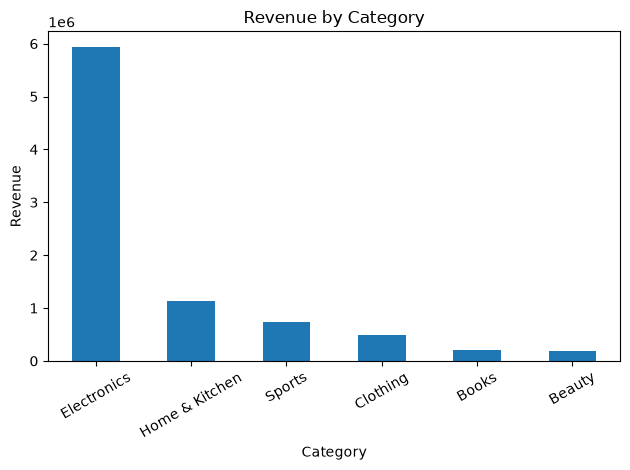

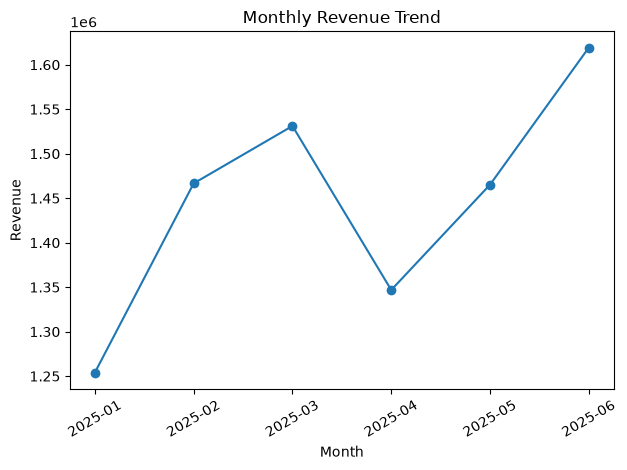

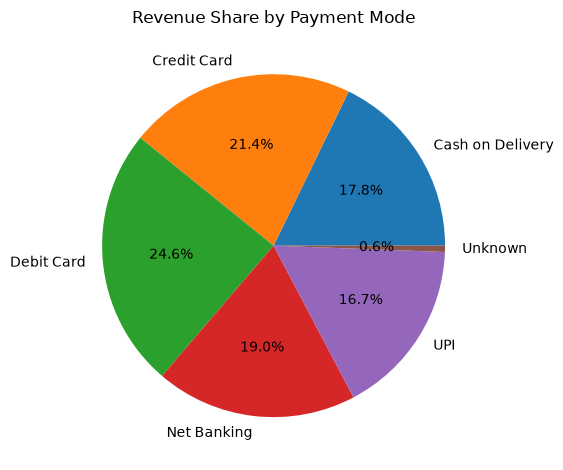

In [5]:
category_sales = sales.groupby('Category')['Total Amount'].sum().sort_values(ascending=False)
category_sales.plot(kind='bar', title='Revenue by Category'); plt.ylabel('Revenue'); plt.xticks(rotation=30); plt.tight_layout(); plt.show()
monthly = sales.assign(Month=sales['Order Date'].dt.to_period('M').astype(str)).groupby('Month')['Total Amount'].sum()
monthly.plot(marker='o', title='Monthly Revenue Trend'); plt.ylabel('Revenue'); plt.xticks(rotation=30); plt.tight_layout(); plt.show()
payment = sales.groupby('Payment Mode')['Total Amount'].sum()
payment.plot(kind='pie', autopct='%1.1f%%', title='Revenue Share by Payment Mode', ylabel=''); plt.tight_layout(); plt.show()

## 5. Business Insights
- 2025-06 recorded the highest completed-sales revenue at 1,619,256.61.
- 2025-01 recorded the lowest completed-sales revenue at 1,253,978.02.
- Electronics is the top revenue-generating category, contributing approximately 68.4% of completed-sales revenue.
- Laptop is the top revenue-generating product in the cleaned completed-sales dataset.
- Jaipur has the highest number of completed orders with 59 orders.
- The average completed order value is 23,659.42, providing a benchmark for typical customer order size.
- 1075 units were sold across 367 completed orders in the analysis period.
- Debit Card contributes the largest share of completed-sales revenue among payment modes.

## 6. Recommendations
- Focus promotions on strong revenue categories while reviewing weaker categories.
- Study the highest-performing month for repeatable campaign or seasonal factors.
- Use city-level order concentration to guide local marketing and delivery capacity.
- Encourage repeat purchases through retention offers.
- Keep the strongest payment methods convenient for customers.